# Data Cleaning and Exploratory Analysis
**MSP470S project, notebook 2 of 4**

| | |
|---|---|
| **Project title** | Talent Matching: A Graph Neural Network Recommender for Ranking Candidate–Employer Matches |
| **Author** | Luyolo Sokatsha (student number 217148875) |
| **Module** | MSP470S Mathematical Sciences Project 4 |
| **Qualification** | Advanced Diploma in Mathematical Sciences |
| **Institution** | Cape Peninsula University of Technology (CPUT) |
| **Date** | November 2026 |

## Project in one paragraph
Talent-matching platforms must decide which employers to show each candidate first. This project compares a graph neural network (GNN) with simpler recommenders (popularity, BPR matrix factorisation, logistic regression) on **fully synthetic** candidate–employer data, using a time-based test, Recall@K and NDCG@K, an ablation, a cold-start test and a sensitivity analysis. No real people, companies or confidential records are used.

## What this notebook does
Prints a data situation report, fixes every problem with a documented decision (nothing is dropped silently; a cleaning log is saved), explores sparsity, popularity, monthly volume, sector/region match and skills overlap, and builds the time-based split (train months 1–16, validation 17–20, test 21–24) with a 10% cold-start candidate group.

| | |
|---|---|
| **Needs** | Notebook 01 output (`data/*.csv`). |
| **Produces** | `data/candidates_clean.csv`, `data/employers_clean.csv`, `data/interactions_clean.csv`, `data/cleaning_log.csv` |
| **Run time** | About 30 seconds |

## How to run
1. In Google Colab choose **Runtime → Run all** (or run the cells from top to bottom). A GPU is not required.
2. The setup cell can mount your Google Drive so that all files are kept between sessions in the folder `MyDrive/MSP470S_Project`. Set `USE_DRIVE = False` to work in temporary Colab storage instead.
3. Run the four notebooks in order: 01 → 02 → 03 → 04 (04 is optional and slow).

In [ ]:

import os, sys
USE_DRIVE = True
if "google.colab" in sys.modules and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORKDIR = "/content/drive/MyDrive/MSP470S_Project"
elif "google.colab" in sys.modules:
    WORKDIR = "/content/MSP470S_Project"
else:
    WORKDIR = os.environ.get("MSP_WORKDIR", os.path.abspath("MSP470S_Project"))
for sub in ("data", "results", "results_sensitivity"):
    os.makedirs(f"{WORKDIR}/{sub}", exist_ok=True)
print("Working folder:", WORKDIR)

Mounted at /content/drive
Working folder: /content/drive/MyDrive/MSP470S_Project


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
os.chdir(f"{WORKDIR}/data")
for f in ("candidates.csv", "employers.csv", "interactions.csv"):
    assert os.path.exists(f), f"{f} not found in {os.getcwd()} - run Notebook 01 first"

cand  = pd.read_csv("candidates.csv")
emp   = pd.read_csv("employers.csv")
inter = pd.read_csv("interactions.csv", parse_dates=["event_date"])
print(cand.shape, emp.shape, inter.shape)
cand.head()

(2000, 7) (300, 6) (24271, 5)


,candidate_id,years_experience,education_level,sector_preference,region,expected_salary_zar,skills
0,1,8.2,Diploma,Logistics,Western Cape,390000.0,accounting|nursing|engineering|operations
1,2,11.7,Masters,Retail,Gauteng,617000.0,python|excel|accounting|sales|project_mgmt|des...
2,3,13.6,Degree,Retail,Gauteng,638000.0,python|project_mgmt|design|finance_modelling
3,4,1.9,Degree,Finance,Gauteng,302000.0,python|negotiation|writing|operations
4,5,3.6,Diploma,Education,Western Cape,258000.0,python|sql|excel|accounting|sales|project_mgmt...


## 1. Data situation report (always first)

In [ ]:
def report(df, name):
    r = pd.DataFrame({"missing_pct": (df.isna().mean()*100).round(2), "dtype": df.dtypes.astype(str), "n_unique": df.nunique()})
    print(f"--- {name} ({len(df)} rows) ---"); print(r); print()
for df, n in [(cand,"candidates"),(emp,"employers"),(inter,"interactions")]: report(df, n)

print("Duplicate candidate ids:", cand.candidate_id.duplicated().sum())
print("Experience outside 0-40:", ((cand.years_experience<0)|(cand.years_experience>40)).sum())
print("Expected salary <= 0:", (cand.expected_salary_zar<=0).sum())
print("Region spellings:", sorted(cand.region.unique()))
print("Duplicate interaction rows:", inter.duplicated(["candidate_id","employer_id","event_date","event_type"]).sum())
print("Future-dated interactions:", (inter.event_date > "2026-10-31").sum())
print("Interactions with unknown employer:", (~inter.employer_id.isin(emp.employer_id)).sum())
print("Interactions with unknown candidate:", (~inter.candidate_id.isin(cand.candidate_id)).sum())

--- candidates (2000 rows) ---
                     missing_pct    dtype  n_unique
candidate_id                0.00    int64      2000
years_experience            0.00  float64       213
education_level             2.00   object         5
sector_preference           0.00   object         8
region                      0.00   object         8
expected_salary_zar         3.95  float64       525
skills                      0.00   object      1969

--- employers (300 rows) ---
                    missing_pct    dtype  n_unique
employer_id                 0.0    int64       300
sector                      0.0   object         8
region                      0.0   object         4
size_band                   0.0   object         3
offered_salary_zar          5.0  float64       181
required_skills             0.0   object       298

--- interactions (24271 rows) ---
                missing_pct           dtype  n_unique
interaction_id          0.0           int64     24231
candidate_id           

## 2. Cleaning — one documented decision per fix, with a log

In [ ]:
log = []
def note(step, before, after, why): log.append({"step": step, "rows_before": before, "rows_after": after, "decision": why})

c = cand.copy()
# a) standardise region spellings
region_map = {"western cape":"Western Cape","w cape":"Western Cape","kzn":"KwaZulu-Natal"}
c["region"] = c["region"].str.strip()
c["region"] = c["region"].apply(lambda r: region_map.get(r.lower(), r))
print("Regions after cleaning:", sorted(c.region.unique()))
# b) impossible experience -> missing, then median-impute (flag kept)
bad_exp = (c.years_experience<0)|(c.years_experience>40)
c["exp_was_invalid"] = bad_exp.astype(int)
c.loc[bad_exp,"years_experience"] = np.nan
c["years_experience"] = c["years_experience"].fillna(c["years_experience"].median())
note("fix invalid experience", len(c), len(c), f"{bad_exp.sum()} values outside 0-40 set to median, flag column kept")
# c) salary: zero/missing -> NaN, impute with median by education level, keep flag
c.loc[c.expected_salary_zar<=0,"expected_salary_zar"] = np.nan
c["salary_was_missing"] = c.expected_salary_zar.isna().astype(int)
c["expected_salary_zar"] = c.groupby("education_level")["expected_salary_zar"].transform(lambda s: s.fillna(s.median()))
c["expected_salary_zar"] = c["expected_salary_zar"].fillna(c["expected_salary_zar"].median())
note("impute salary", len(c), len(c), "zero/missing salary filled with education-level median; flag kept")
# d) education missing -> 'Unknown' (do not silently drop)
n_edu = c.education_level.isna().sum(); c["education_level"] = c["education_level"].fillna("Unknown")
note("education missing", len(c), len(c), f"{n_edu} missing set to 'Unknown'")

e = emp.copy()
n_sal = e.offered_salary_zar.isna().sum()
e["offered_salary_zar"] = e.groupby("size_band")["offered_salary_zar"].transform(lambda s: s.fillna(s.median()))
note("impute employer salary", len(e), len(e), f"{n_sal} missing filled with size-band median")

i = inter.copy(); n0 = len(i)
i = i.drop_duplicates(["candidate_id","employer_id","event_date","event_type"]); note("drop duplicate interactions", n0, len(i), "exact duplicates removed")
n0 = len(i); i = i[i.employer_id.isin(e.employer_id) & i.candidate_id.isin(c.candidate_id)]; note("drop orphan keys", n0, len(i), "employer/candidate id not in master tables")
n0 = len(i); i = i[i.event_date <= "2026-10-31"]; note("drop future dates", n0, len(i), "events dated after the data window")

pd.DataFrame(log)

Regions after cleaning: ['Eastern Cape', 'Gauteng', 'KwaZulu-Natal', 'Western Cape']


,step,rows_before,rows_after,decision
0,fix invalid experience,2000,2000,"20 values outside 0-40 set to median, flag col..."
1,impute salary,2000,2000,zero/missing salary filled with education-leve...
2,education missing,2000,2000,40 missing set to 'Unknown'
3,impute employer salary,300,300,15 missing filled with size-band median
4,drop duplicate interactions,24271,24232,exact duplicates removed
5,drop orphan keys,24232,24184,employer/candidate id not in master tables
6,drop future dates,24184,24088,events dated after the data window


## 3. Exploration

Candidates 2000, employers 300, unique pairs 24088
Grid density: 4.01%  (sparsity 95.99%)
event_type
applied        0.560
shortlisted    0.305
hired          0.135
Name: proportion, dtype: float64


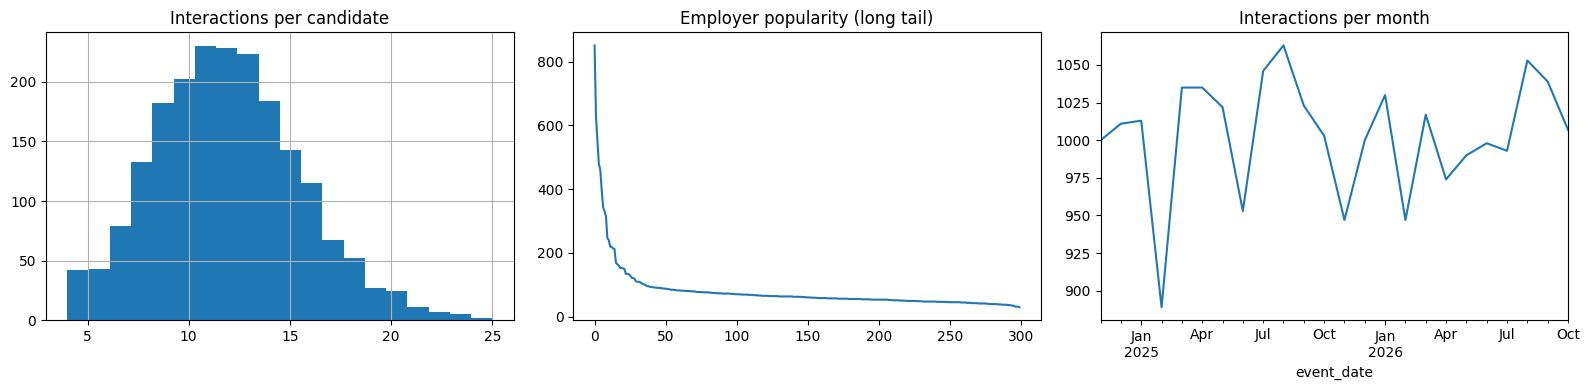

In [ ]:
# 3.1 Size and sparsity of the candidate-employer grid
pairs = i[["candidate_id","employer_id"]].drop_duplicates().shape[0]
print(f"Candidates {len(c)}, employers {len(e)}, unique pairs {pairs}")
print(f"Grid density: {pairs/(len(c)*len(e)):.2%}  (sparsity {1-pairs/(len(c)*len(e)):.2%})")
print(i.event_type.value_counts(normalize=True).round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
i.groupby("candidate_id").size().hist(bins=20, ax=ax[0]); ax[0].set_title("Interactions per candidate")
i.groupby("employer_id").size().sort_values(ascending=False).reset_index(drop=True).plot(ax=ax[1]); ax[1].set_title("Employer popularity (long tail)")
i.set_index("event_date").resample("MS").size().plot(ax=ax[2]); ax[2].set_title("Interactions per month")
plt.tight_layout(); plt.show()

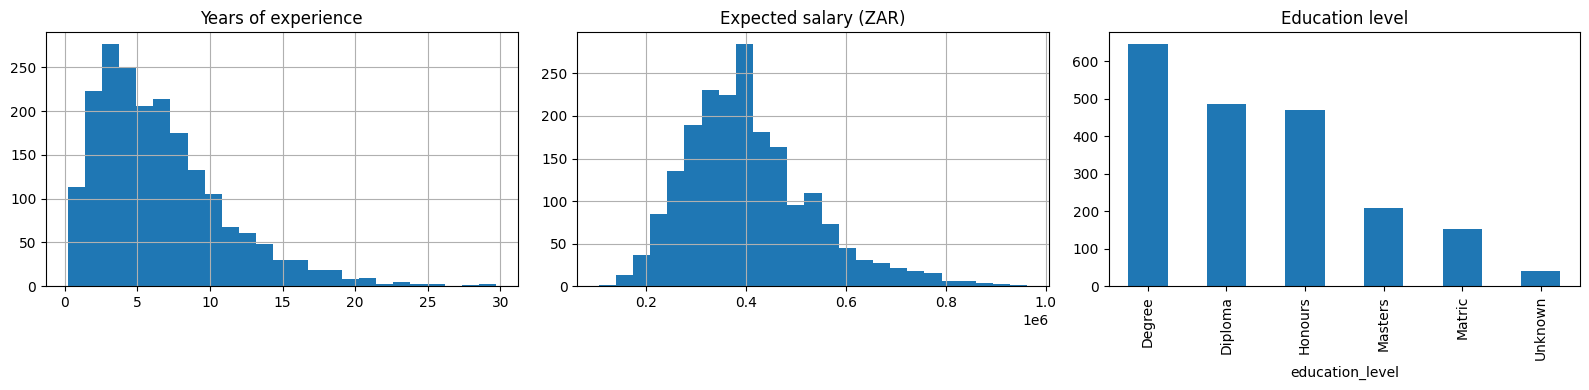

Share of interactions where sector matches: 0.292
Share of interactions where region matches: 0.41
Hire rate by sector match:
False    0.112
True     0.192
Name: hired, dtype: float64


sector,Education,Energy,Finance,Healthcare,Logistics,Manufacturing,Retail,Technology
sector_preference,,,,,,,,
Education,0.37,0.07,0.09,0.11,0.08,0.09,0.09,0.10
Energy,0.16,0.26,0.09,0.11,0.08,0.10,0.08,0.12
Finance,0.14,0.07,0.27,0.12,0.09,0.09,0.09,0.12
Healthcare,0.15,0.08,0.09,0.30,0.09,0.10,0.09,0.11
Logistics,0.15,0.08,0.09,0.11,0.25,0.09,0.10,0.13
Manufacturing,0.15,0.08,0.08,0.11,0.08,0.30,0.09,0.13
Retail,0.15,0.08,0.08,0.11,0.10,0.10,0.25,0.13
Technology,0.14,0.07,0.08,0.11,0.08,0.10,0.09,0.34


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
c.years_experience.hist(bins=25, ax=ax[0]); ax[0].set_title("Years of experience")
c.expected_salary_zar.hist(bins=25, ax=ax[1]); ax[1].set_title("Expected salary (ZAR)")
c.education_level.value_counts().plot.bar(ax=ax[2]); ax[2].set_title("Education level")
plt.tight_layout(); plt.show()

m = i.merge(c[["candidate_id","sector_preference","region"]], on="candidate_id").merge(e[["employer_id","sector","region"]], on="employer_id", suffixes=("_cand","_emp"))
print("Share of interactions where sector matches:", (m.sector_preference==m.sector).mean().round(3))
print("Share of interactions where region matches:", (m.region_cand==m.region_emp).mean().round(3))
print("Hire rate by sector match:"); print(m.assign(hired=(m.event_type=="hired")).groupby(m.sector_preference==m.sector)["hired"].mean().round(3))
pd.crosstab(m.sector_preference, m.sector, normalize="index").round(2)

In [ ]:
# 3.2 Skills: how many per person and how much candidates overlap with the employers they interact with
c["n_skills"] = c.skills.str.split("|").str.len()
print(c.n_skills.describe().round(2))
cs = c.set_index("candidate_id").skills.str.split("|").apply(set); es = e.set_index("employer_id").required_skills.str.split("|").apply(set)
m["overlap"] = [len(cs[a] & es[b]) / max(len(es[b]),1) for a,b in zip(m.candidate_id, m.employer_id)]
print(m.groupby("event_type")["overlap"].mean().round(3))   # higher overlap should go with better outcomes

count    2000.0
mean        5.7
std         1.4
min         3.0
25%         5.0
50%         6.0
75%         7.0
max         8.0
Name: n_skills, dtype: float64
event_type
applied        0.361
hired          0.417
shortlisted    0.361
Name: overlap, dtype: float64


## 4. Time-based split (never random) — train on earlier events, test on the latest

In [ ]:
train = i[i.event_date <  "2026-03-01"]     # months 1-16
valid = i[(i.event_date >= "2026-03-01") & (i.event_date < "2026-07-01")]   # months 17-20
test  = i[i.event_date >= "2026-07-01"]     # months 21-24
print(len(train), len(valid), len(test))

# cold-start group: a random 10% of candidates are hidden from training and scored from their profile only
rng = np.random.default_rng(470)
cold_ids = set(rng.choice(c.candidate_id, int(0.10*len(c)), replace=False))
train_warm = train[~train.candidate_id.isin(cold_ids)]
test_cold  = test[test.candidate_id.isin(cold_ids)]
test_warm  = test[~test.candidate_id.isin(cold_ids)]
print("Cold-start candidates:", len(cold_ids), "| training rows after removing them:", len(train_warm))
print("Test rows, warm candidates:", len(test_warm), "| cold candidates:", len(test_cold))

16017 3979 4092
Cold-start candidates: 200 | training rows after removing them: 14411
Test rows, warm candidates: 3713 | cold candidates: 379


## 5. Save the cleaned files for the modelling notebook

In [ ]:
c.to_csv("candidates_clean.csv", index=False); e.to_csv("employers_clean.csv", index=False); i.to_csv("interactions_clean.csv", index=False)
pd.DataFrame(log).to_csv("cleaning_log.csv", index=False)
print("saved: candidates_clean.csv, employers_clean.csv, interactions_clean.csv, cleaning_log.csv")

saved: candidates_clean.csv, employers_clean.csv, interactions_clean.csv, cleaning_log.csv
